# Session 6 · Notebook 4 — Pushing EfficientNet to the limit
Session 6 deck, *Working with CNNs (II): transfer learning*. Run in Colab with a GPU (Runtime → Change runtime type → T4 GPU).

What is the best test accuracy we can reach on Cats vs Dogs? Everything at once:
- a **bigger EfficientNet** at its native resolution (default: **EfficientNetB3 at 300×300**;
  try `EfficientNetV2S`);
- **mixed precision** (float16 on the GPU's tensor cores): ~2× faster, half the memory;
- phase 1 (head) then phase 2: **unfreeze the whole base** (BatchNorm frozen), AdamW + **cosine decay**,
  **label smoothing**, EarlyStopping + ModelCheckpoint;
- **test-time augmentation** (TTA): average the prediction of each test image and its mirror.

At this level the remaining errors are often **label mistakes** or impossible images: look at them.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow info messages
import json, time, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
print("Keras", keras.__version__, "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(1337)
os.makedirs("results", exist_ok=True)

I0000 00:00:1792087281.403107   51145 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792087282.908041   51145 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
MIXED_PRECISION = True
if MIXED_PRECISION and tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")
print("policy:", keras.mixed_precision.global_policy().name)

policy: mixed_float16


In [3]:
IMG_SIZE = (300, 300)  # pretrained ImageNet models were trained at 224 x 224 (or larger)
BATCH = 64                 # same batch size as Session 5 => exactly the same test images
SEED = 1337                # same seed as Session 5 => same train / val / test split
WEIGHTS = "imagenet"       # pretrained weights (None = random weights, only for testing the code)
QUICK = False              # True: ~20% of the training batches (fast trial run)

BASE_NAME = "EfficientNetB3"   # or "EfficientNetV2S" (larger, slower)
PHASE1_EPOCHS, PHASE2_EPOCHS = 3, 15
TRAIN_BATCH = 32               # training batch size; lower it (16, 8) if the GPU runs out of memory.
                               # The split still uses BATCH = 64, so the test set does not change.
UNFREEZE_FRACTION = 1.0        # 1.0 = whole base; 0.5 = top half (less memory, a bit faster)

In [4]:
# --- 1. Download the Kaggle Cats and Dogs data (Microsoft PetImages) -----------------------------
URL = ("https://download.microsoft.com/download/3/E/1/"
       "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip")
DATA_DIR = "PetImages"
if not os.path.isdir(DATA_DIR):
    print("Downloading (about 790 MB)...")
    urllib.request.urlretrieve(URL, "catsdogs.zip")
    with zipfile.ZipFile("catsdogs.zip") as z:
        z.extractall(".")
    os.remove("catsdogs.zip")

# --- 2. Clean once, in two steps -----------------------------------------------------------------
# (a) EXACTLY the Session 5 rule: delete every file without a JFIF header. This keeps the same files
#     as Session 5, so the 70/15/15 split and the 3,503 test images are identical.
# (b) Re-encode the remaining files as standard RGB JPEGs (removes the "Corrupt JPEG data" warnings);
#     delete any file that still cannot be opened.
from PIL import Image
import shutil
MARK = os.path.join(DATA_DIR, ".cleaned_v2")
if os.path.exists(os.path.join(DATA_DIR, ".cleaned")) and not os.path.exists(MARK):
    # folder cleaned by an earlier version of this notebook: the JFIF rule can no longer be applied
    print("Old cleaning detected: downloading the data again...")
    shutil.rmtree(DATA_DIR)
    urllib.request.urlretrieve(URL, "catsdogs.zip")
    with zipfile.ZipFile("catsdogs.zip") as z:
        z.extractall(".")
    os.remove("catsdogs.zip")
if not os.path.exists(MARK):
    no_jfif, unreadable = [], []
    for folder in ("Cat", "Dog"):
        path = os.path.join(DATA_DIR, folder)
        for fname in os.listdir(path):
            fpath = os.path.join(path, fname)
            try:                                              # (a) Session 5 rule
                with open(fpath, "rb") as f:
                    ok = b"JFIF" in f.peek(10)
            except OSError:
                ok = False
            if not ok:
                os.remove(fpath); no_jfif.append(f"{folder}/{fname}"); continue
            try:                                              # (b) re-encode
                with Image.open(fpath) as im:
                    im = im.convert("RGB"); im.load()
                im.save(fpath, "JPEG", quality=95)
            except Exception:
                os.remove(fpath); unreadable.append(f"{folder}/{fname}")
    open(MARK, "w").write("\n".join(no_jfif + unreadable))
    print(len(no_jfif), "files without JFIF header removed (as in Session 5);",
          len(unreadable), "unreadable files removed")
for folder in ("Cat", "Dog"):
    print(folder, len(os.listdir(os.path.join(DATA_DIR, folder))), "images")

Cat 11741 images
Dog 11669 images


In [5]:
# --- 3. Train / validation / test: 70 / 15 / 15, identical to Session 5 --------------------------
# Session 5 had 3,503 test images; if the line below shows another number, the files differ.
train_ds, rest_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.3, subset="both", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")
class_names = train_ds.class_names
n_rest = int(rest_ds.cardinality())
val_ds, test_ds = rest_ds.take(n_rest // 2), rest_ds.skip(n_rest // 2)
if QUICK:
    train_ds = train_ds.take(int(train_ds.cardinality()) // 5)
N_TRAIN, N_VAL, N_TEST = (int(d.cardinality()) for d in (train_ds, val_ds, test_ds))
AUTOTUNE = tf.data.AUTOTUNE
train_ds, val_ds, test_ds = (d.prefetch(AUTOTUNE) for d in (train_ds, val_ds, test_ds))
print(class_names, "| batches of", BATCH, ": train", N_TRAIN, "val", N_VAL, "test", N_TEST)

Found 23410 files belonging to 2 classes.
Using 16387 files for training.
Using 7023 files for validation.
['Cat', 'Dog'] | batches of 64 : train 257 val 55 test 55


In [6]:
# Re-batch ONLY the training data (memory). Validation/test keep the Session 5 batches => same test set.
train_ds = train_ds.unbatch().batch(TRAIN_BATCH).prefetch(AUTOTUNE)
N_TRAIN = int(np.ceil(N_TRAIN * BATCH / TRAIN_BATCH))      # steps per epoch (used by the cosine schedule)
print("training batches of", TRAIN_BATCH, ":", N_TRAIN)

training batches of 32 : 514


In [7]:
def make_augmentation():          # a new instance for each model (models may use different image sizes)
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
    ], name="augmentation")

In [8]:
# --- The transfer-learning model: augmentation -> preprocessing -> pretrained base -> new head ----
# The base and the head are separate sub-models: we can freeze the base, and Grad-CAM (Notebook 5)
# can read the base output (the last convolutional feature maps).
BASES = {
    "ResNet50": (keras.applications.ResNet50, keras.applications.resnet.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    "EfficientNetB3": (keras.applications.EfficientNetB3, keras.applications.efficientnet.preprocess_input),
    "EfficientNetV2S": (keras.applications.EfficientNetV2S, keras.applications.efficientnet_v2.preprocess_input),
}

def build_transfer(base_name, dropout=0.2, img_size=None, weights="default"):
    img_size = img_size or IMG_SIZE
    make_base, preprocess = BASES[base_name]
    base = make_base(include_top=False, weights=WEIGHTS if weights == "default" else weights,
                     input_shape=tuple(img_size) + (3,))
    base.trainable = False                                   # phase 1: frozen
    head = keras.Sequential([
        keras.Input(base.output.shape[1:]),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid", dtype="float32"),   # float32 output (mixed precision)
    ], name="head")
    inputs = keras.Input(shape=tuple(img_size) + (3,))       # raw pixels 0..255
    x = make_augmentation()(inputs)
    x = layers.Lambda(preprocess, name="preprocess")(x)       # the base's OWN normalisation
    x = base(x, training=False)                               # BN always in inference mode
    outputs = head(x)
    return keras.Model(inputs, outputs, name=f"tl_{base_name}"), base

def count(model):
    tr = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    return model.count_params(), tr

def unfreeze(base, n_last=None):
    """Make the last n_last layers of the base trainable (None = all). BatchNorm stays frozen."""
    base.trainable = True
    layers_ = base.layers if n_last is None else base.layers[-n_last:]
    for l in base.layers:
        l.trainable = l in layers_ and not isinstance(l, layers.BatchNormalization)

In [9]:
# --- Evaluation helpers (as in Session 5) ---------------------------------------------------------
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

def evaluate(model, ds, name, tta=False):
    y_true, p, imgs = [], [], []
    for x, y in ds:
        pr = model.predict(x, verbose=0)[:, 0]
        if tta:                                    # test-time augmentation: average with the mirror image
            pr = 0.5 * (pr + model.predict(tf.image.flip_left_right(x), verbose=0)[:, 0])
        p.append(pr); y_true.append(y.numpy()[:, 0])
        if len(imgs) < 6: imgs.append(x.numpy().astype("uint8"))
    y_true, p = np.concatenate(y_true).astype(int), np.concatenate(p)
    y_pred = (p >= 0.5).astype(int)
    acc = float((y_true == y_pred).mean()); cm = confusion_matrix(y_true, y_pred)
    print(f"{name}: test accuracy = {acc:.4f} on {len(y_true)} images | errors: {int((y_true != y_pred).sum())}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Purples", colorbar=False)
    ax.set_title(f"{name} -- test accuracy {acc:.2%}")
    fig.tight_layout(); fig.savefig(f"results/{name}_cm.png", dpi=600); plt.show()
    return dict(acc=acc, cm=cm.tolist(), y_true=y_true, p=p, imgs=np.concatenate(imgs))

def plot_history(hs, name, labels):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    start = 0
    for h, lab in zip(hs, labels):
        ep = range(start + 1, start + len(h["loss"]) + 1)
        for k, a in [("accuracy", ax[0]), ("loss", ax[1])]:
            a.plot(ep, h[k], "--", label=f"train ({lab})"); a.plot(ep, h["val_" + k], label=f"val ({lab})")
        start += len(h["loss"])
    for k, a in [("accuracy", ax[0]), ("loss", ax[1])]:
        a.set_xlabel("epoch"); a.set_title(k); a.grid(alpha=.3); a.legend(fontsize=7)
    if len(hs) > 1:
        for a in ax: a.axvline(len(hs[0]["loss"]) + 0.5, color="grey", ls=":")
    fig.tight_layout(); fig.savefig(f"results/{name}_curves.png", dpi=600); plt.show()

def show_errors(res, name, n=10):
    k = len(res["imgs"]); wrong = np.where((res["p"][:k] >= 0.5) != res["y_true"][:k])[0][:n]
    if len(wrong) == 0: print("no errors in the first batches"); return
    fig, ax = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.4))
    for a, i in zip(np.atleast_1d(ax), wrong):
        a.imshow(res["imgs"][i]); a.axis("off")
        a.set_title(f"true {class_names[res['y_true'][i]]}\nP(dog)={res['p'][i]:.2f}", fontsize=8)
    fig.tight_layout(); fig.savefig(f"results/{name}_errors.png", dpi=600); plt.show()

def save_summary(name, model, hs, res, secs, extra=None):
    total, trainable = count(model)
    s = dict(name=name, params=total, test_acc=res["acc"], cm=res["cm"], minutes=round(secs / 60, 1),
             epochs=sum(len(h["loss"]) for h in hs),
             best_val_acc=float(max(max(h["val_accuracy"]) for h in hs)), **(extra or {}))
    json.dump(dict(summary=s, histories=hs), open(f"results/{name}.json", "w"))
    print(json.dumps(s, indent=1))
    print(f"\n>>> for the slides: test accuracy = {100*res['acc']:.2f}% | errors = "
          f"{int(round((1-res['acc'])*len(res['y_true'])))} | training time = {secs/60:.1f} min | "
          f"weights = {total:,}")

def fit(model, epochs, lr, name, callbacks=None, wd=None, label_smoothing=0.0, schedule=False):
    steps = epochs * N_TRAIN
    rate = keras.optimizers.schedules.CosineDecay(lr, steps) if schedule else lr
    opt = keras.optimizers.AdamW(rate, weight_decay=wd) if wd else keras.optimizers.Adam(rate)
    model.compile(optimizer=opt, loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing),
                  metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks or [])
    secs = time.time() - t0
    print(f"{name}: {secs/60:.1f} min, {secs/max(1,len(h.history['loss'])):.0f} s/epoch")
    return {k: [float(v) for v in vs] for k, vs in h.history.items()}, secs

In [10]:
model, base = build_transfer(BASE_NAME, dropout=0.3)
h1, s1 = fit(model, PHASE1_EPOCHS, 1e-3, "phase 1 (frozen)", label_smoothing=0.1)

E0000 00:00:1792087299.923620   51145 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Epoch 1/3
    513/Unknown 74s 105ms/step - accuracy: 0.9593 - loss: 0.2954

/home/jaumemanero/ML/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


513/513 ━━━━━━━━━━━━━━━━━━━━ 94s 146ms/step - accuracy: 0.9802 - loss: 0.2540 - val_accuracy: 0.9946 - val_loss: 0.2224
Epoch 2/3
513/513 ━━━━━━━━━━━━━━━━━━━━ 60s 117ms/step - accuracy: 0.9876 - loss: 0.2327 - val_accuracy: 0.9946 - val_loss: 0.2182
Epoch 3/3
513/513 ━━━━━━━━━━━━━━━━━━━━ 60s 117ms/step - accuracy: 0.9892 - loss: 0.2297 - val_accuracy: 0.9952 - val_loss: 0.2166
phase 1 (frozen): 3.6 min, 71 s/epoch


In [11]:
n_unfreeze = None if UNFREEZE_FRACTION >= 1 else int(len(base.layers) * UNFREEZE_FRACTION)
unfreeze(base, n_last=n_unfreeze)    # all (or the top part of the) layers, except BatchNorm
total, trainable = count(model)
print(f"trainable weights: {trainable:,} of {total:,}")
cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
      keras.callbacks.ModelCheckpoint("results/nb4_best.weights.h5", monitor="val_accuracy",
                                      save_best_only=True, save_weights_only=True)]
h2, s2 = fit(model, PHASE2_EPOCHS, 3e-5, "phase 2 (fine-tune all)", callbacks=cb,
             wd=1e-5, label_smoothing=0.1, schedule=True)

trainable weights: 10,610,473 of 10,785,072
Epoch 1/15
513/513 ━━━━━━━━━━━━━━━━━━━━ 312s 463ms/step - accuracy: 0.9922 - loss: 0.2173 - val_accuracy: 0.9969 - val_loss: 0.2063
Epoch 2/15
513/513 ━━━━━━━━━━━━━━━━━━━━ 193s 375ms/step - accuracy: 0.9957 - loss: 0.2095 - val_accuracy: 0.9969 - val_loss: 0.2055
Epoch 3/15
513/513 ━━━━━━━━━━━━━━━━━━━━ 198s 386ms/step - accuracy: 0.9976 - loss: 0.2056 - val_accuracy: 0.9963 - val_loss: 0.2047
Epoch 4/15
513/513 ━━━━━━━━━━━━━━━━━━━━ 195s 381ms/step - accuracy: 0.9971 - loss: 0.2061 - val_accuracy: 0.9969 - val_loss: 0.2046
Epoch 5/15
513/513 ━━━━━━━━━━━━━━━━━━━━ 197s 383ms/step - accuracy: 0.9982 - loss: 0.2039 - val_accuracy: 0.9974 - val_loss: 0.2037
Epoch 6/15
513/513 ━━━━━━━━━━━━━━━━━━━━ 199s 387ms/step - accuracy: 0.9987 - loss: 0.2025 - val_accuracy: 0.9972 - val_loss: 0.2041
Epoch 7/15
513/513 ━━━━━━━━━━━━━━━━━━━━ 195s 381ms/step - accuracy: 0.9993 - loss: 0.2017 - val_accuracy: 0.9974 - val_loss: 0.2034
Epoch 8/15
513/513 ━━━━━━━━━━━━━

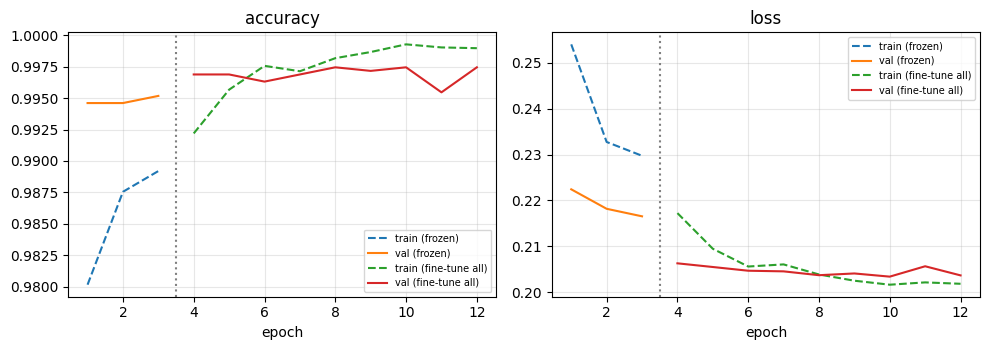

nb4: test accuracy = 0.9971 on 3503 images | errors: 10
              precision    recall  f1-score   support

         Cat      0.998     0.996     0.997      1760
         Dog      0.996     0.998     0.997      1743

    accuracy                          0.997      3503
   macro avg      0.997     0.997     0.997      3503
weighted avg      0.997     0.997     0.997      3503



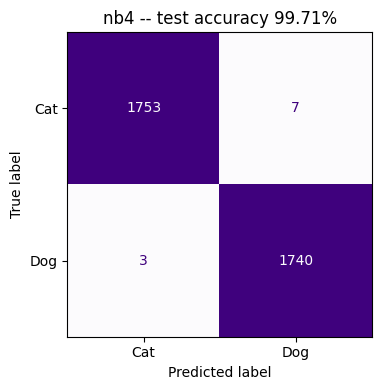

nb4_tta: test accuracy = 0.9977 on 3503 images | errors: 8
              precision    recall  f1-score   support

         Cat      0.999     0.997     0.998      1760
         Dog      0.997     0.999     0.998      1743

    accuracy                          0.998      3503
   macro avg      0.998     0.998     0.998      3503
weighted avg      0.998     0.998     0.998      3503



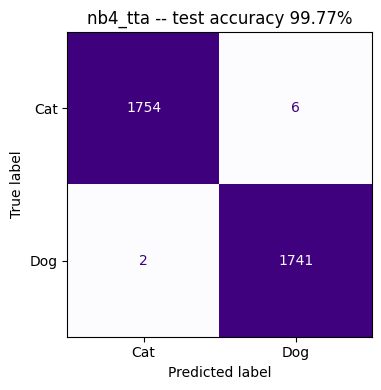

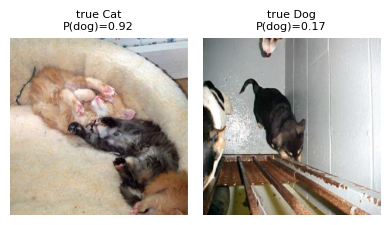

{
 "name": "nb4",
 "params": 10785072,
 "test_acc": 0.9977162432200971,
 "cm": [
  [
   1754,
   6
  ],
  [
   2,
   1741
  ]
 ],
 "minutes": 35.3,
 "epochs": 12,
 "best_val_acc": 0.9974431991577148,
 "trainable": 10610473,
 "acc_without_tta": 0.9971453040251214,
 "base": "EfficientNetB3",
 "img": 300
}

>>> for the slides: test accuracy = 99.77% | errors = 8 | training time = 35.3 min | weights = 10,785,072


In [12]:
plot_history([h1, h2], "nb4", ["frozen", "fine-tune all"])
res = evaluate(model, test_ds, "nb4")
res_tta = evaluate(model, test_ds, "nb4_tta", tta=True)
show_errors(res_tta, "nb4")
save_summary("nb4", model, [h1, h2], res_tta, s1 + s2,
             extra=dict(trainable=trainable, acc_without_tta=res["acc"], base=BASE_NAME, img=IMG_SIZE[0]))
model.save_weights("results/nb4.weights.h5")

## All the errors on the test set: model mistakes, or label mistakes?

8 errors out of 3503


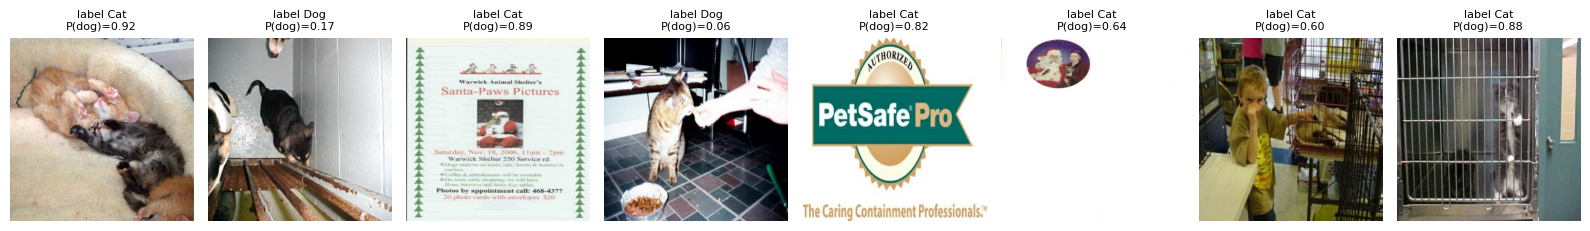

In [13]:
errs = np.where((res_tta["p"] >= 0.5) != res_tta["y_true"])[0]
print(len(errs), "errors out of", len(res_tta["y_true"]))
imgs_all = np.concatenate([x.numpy().astype("uint8") for x, _ in test_ds])
k = min(24, len(errs)); cols = 8
if k == 0:
    print("no errors at all!")
else:
  fig, ax = plt.subplots(int(np.ceil(k / cols)), cols, figsize=(16, 2.3 * np.ceil(k / cols)), squeeze=False)
  for a in ax.flat: a.axis("off")
  for a, i in zip(ax.flat, errs[:k]):
      a.imshow(imgs_all[i]); a.set_title(f"label {class_names[res_tta['y_true'][i]]}\nP(dog)={res_tta['p'][i]:.2f}", fontsize=8)
  fig.tight_layout(); fig.savefig("results/nb4_all_errors.png", dpi=150); plt.show()

## The leaderboard
Session 5 from scratch: 96.3 %. How far did transfer learning take us? Try: `EfficientNetV2S`, more epochs in
phase 2, a larger image size, stronger augmentation. **Same rule as in Session 5: the test set is evaluated once.**